# Corte 2 — Benchmark, validación y análisis de errores
## Proyecto 7: Diagnóstico visual de enfermedades en hojas de tomate

Profundización III — Inteligencia Artificial, 2026-II

Integrantes: Luis Alejandro Zambrano, Jhoan David Santamaría, Juan Norberto Pardo y Edwin Santiago Sandoval.

La regla de oro de este corte es: primero el problema, después la línea base y solo al final la complejidad, siempre que se pueda justificar.

Este cuaderno sigue las seis secciones del miniproyecto de la Semana 2, pero adaptadas a nuestro proyecto, que trabaja con imágenes. Aquí comparamos nueve modelos usando las mismas imágenes y las mismas métricas, revisamos en qué se equivocan y elegimos un modelo provisional.

Para reproducir todo, desde la carpeta principal del repositorio y con el entorno `.venv` activo, se corren estos comandos:

```powershell
python src/c2_run_benchmark.py      # índice + fuga, baselines, 7 CNN, análisis (≈1,5-2 h en GTX 1650)
python src/c2_analyze.py            # solo regenera tablas y figuras a partir de reports/corte2/runs/
```

Este cuaderno no entrena nada. Solo lee los resultados que ya quedaron guardados en la carpeta `reports/corte2/`, así que se puede revisar en pocos segundos.

El conjunto de test no se usó en este corte, ni para entrenar ni para tomar decisiones. Lo único que hicimos con él fue revisar los nombres de sus archivos para documentar el problema de fuga de información que se explica más abajo.

In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import Image, display, Markdown

# Raíz del repo (funciona si el cuaderno se abre desde notebooks/ o desde la raíz)
REPO = Path.cwd()
while not (REPO / "src").exists() and REPO != REPO.parent:
    REPO = REPO.parent
R = REPO / "reports" / "corte2"
FIG = R / "figures"

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
CLASES_ES = {"Tomato___Bacterial_spot": "Mancha bacteriana", "Tomato___Early_blight": "Tizón temprano",
             "Tomato___Late_blight": "Tizón tardío", "Tomato___Leaf_Mold": "Moho de la hoja",
             "Tomato___Septoria_leaf_spot": "Mancha Septoria", "Tomato___healthy": "Sana"}
idx = pd.read_csv(R / "index_corte2.csv")
bench = pd.read_csv(R / "benchmark.csv")
sig = json.load(open(R / "significancia.json", encoding="utf-8"))
print("Repositorio:", REPO)
print("Imágenes indexadas:", len(idx), "| modelos en el benchmark:", len(bench))

Repositorio: /home/claude/real
Imágenes indexadas: 6557 | modelos en el benchmark: 9


---
# 1. Formulación de la tarea y comprensión del dataset

1. ¿Trabajamos con la ruta sintética o con datos propios?

Trabajamos con datos propios del proyecto. Es el dataset Processed Tomato Leaf Disease Image Dataset, publicado en Mendeley Data con licencia CC BY 4.0. Es una versión depurada de PlantVillage, una colección muy conocida de fotos de hojas de cultivos. Como son solo fotos de hojas, no hay ningún dato personal de por medio.

2. ¿Es un problema de clasificación o de regresión?

Es de clasificación. La diferencia es sencilla: en regresión el modelo predice un número, como una temperatura o un consumo de energía, mientras que en clasificación el modelo escoge una categoría entre varias posibles. Aquí la pregunta es qué enfermedad tiene la hoja, o si está sana, así que la respuesta siempre es una categoría. Además es clasificación multiclase, porque hay más de dos opciones.

3. ¿Cuál es la variable objetivo?

Es la clase de la hoja, que puede tomar seis valores: mancha bacteriana, tizón temprano, tizón tardío, moho de la hoja, mancha por Septoria y hoja sana.

4. ¿Qué variables predictoras usamos?

En el fondo, la información de entrada son los píxeles de la foto, es decir, los colores rojo, verde y azul de cada punto de la imagen. Lo que cambia es cómo cada modelo usa esos píxeles. El modelo clásico del Corte 1 no mira la foto directamente: primero la resumimos en 58 números que describen cuánto hay de cada color y cómo es la textura de la hoja, y el modelo trabaja con esos 58 números. Las redes neuronales, en cambio, reciben la foto completa reducida a 224 por 224 píxeles y aprenden por su cuenta qué patrones son importantes.

5. ¿Qué variables descartamos y por qué?

Nunca usamos el nombre del archivo ni la carpeta donde está guardada la foto. Puede sonar obvio, pero es importante, porque el nombre de la carpeta es literalmente la respuesta, y el nombre del archivo trae pistas sobre la sesión en que se tomó la foto. Si el modelo pudiera ver eso, estaría haciendo trampa. Tampoco usamos como entrada las medidas de calidad que calculamos en el Corte 1, como la nitidez o el tamaño del archivo. Esas solo sirvieron para revisar el dataset.

6. ¿Qué tipo de error sería más costoso?

No todos los errores pesan igual. El peor es decirle a alguien que su hoja está sana cuando en realidad está enferma, porque no hace nada, no trata la planta y la enfermedad se sigue regando por el cultivo. A eso se le llama un falso negativo.

El segundo error más grave es confundir el tizón tardío con el tizón temprano. Parecen parecidos a simple vista, pero el tizón tardío avanza mucho más rápido, en cuestión de días, y se trata de forma distinta. Si se confunden, se termina aplicando el tratamiento equivocado. Esta confusión era justamente el punto débil del modelo del Corte 1.

El error menos grave es el contrario: decir que una hoja sana está enferma. Eso se llama falso positivo, y lo que cuesta es una revisión de más o una aplicación de producto que no hacía falta.

Por todo esto, la métrica principal que usamos es el macro-F1. El F1 mide qué tan bien le va al modelo en una clase combinando dos cosas: cuántas veces acierta cuando dice esa clase y cuántos de los casos reales de esa clase logra encontrar. El macro-F1 es el promedio de ese valor entre las seis clases, dándole el mismo peso a cada una, para que una clase difícil no quede escondida detrás de las fáciles. Además de eso, miramos aparte el F1 de los dos tizones y qué tan bien detecta el modelo las hojas sanas.

In [ ]:
conteo = idx.groupby(["split", "class"]).size().unstack(0)[["train", "val", "test"]]
conteo.index = [CLASES_ES[c] for c in conteo.index]
conteo.loc["Total"] = conteo.sum()
conteo

split,train,val,test
Mancha bacteriana,768,164,166
Tizón temprano,762,163,164
Tizón tardío,763,163,165
Moho de la hoja,760,163,164
Mancha Septoria,768,164,166
Sana,765,164,165
Total,4586,981,990


---
# 2. Preparación mínima y plan de validación

Para entrenar y evaluar un modelo, las fotos se dividen en tres grupos. El de entrenamiento, o train, son las fotos con las que el modelo aprende. El de validación son fotos que el modelo nunca ha visto y que usamos para comparar modelos y tomar decisiones. El de test es como el examen final: se guarda sin tocar hasta el Corte 3 para tener una medida honesta al final. El dataset ya trae esta división hecha, con 70 por ciento de las fotos para entrenamiento, 15 por ciento para validación y 15 por ciento para test. Eso da 4.586, 981 y 990 fotos, y cada clase tiene más o menos la misma cantidad.

### Lo que encontramos: fuga de información en el dataset

Cuando armamos el inventario de todas las fotos nos dimos cuenta de algo raro. El proveedor del dataset había creado copias de algunas hojas, rotándolas o recortándolas un poco, para tener más fotos. El problema es que esas copias quedaron repartidas en grupos diferentes. Es decir, había hojas cuya foto original estaba en entrenamiento y una copia girada estaba en validación o en test.

Eso es lo que se conoce como fuga de información, y es un problema serio. Si el modelo ya vio una hoja durante el entrenamiento y luego le mostramos la misma hoja girada para evaluarlo, puede reconocerla en vez de diagnosticarla de verdad. Sería como presentar un examen donde algunas preguntas son las mismas del taller, solo que con otro orden. La nota sale más alta de lo que realmente es.

Para detectarlo, el script `src/c2_build_index.py` lee el nombre de cada copia, que incluye el nombre de la foto original, y así identifica de qué hoja viene cada imagen. También compara el contenido de los archivos por si hubiera fotos idénticas con distinto nombre. Con eso marcamos como contaminada cualquier foto de validación o de test cuya hoja original esté en entrenamiento.

aumentadas           contaminadas          
split                   test train val         test train val
clase                                                        
Mancha Septoria            2     7   0            3     0   1
Mancha bacteriana          0     0   0            0     0   0
Moho de la hoja           26   134  24           38     0  37
Sana                       5    12   1            7     0   5
Tizón tardío               1     3   0            2     0   0
Tizón temprano            22    99  20           32     0  29

val: 72 de 981 imágenes contaminadas (7.3 %)
test: 82 de 990 imágenes contaminadas (8.3 %)


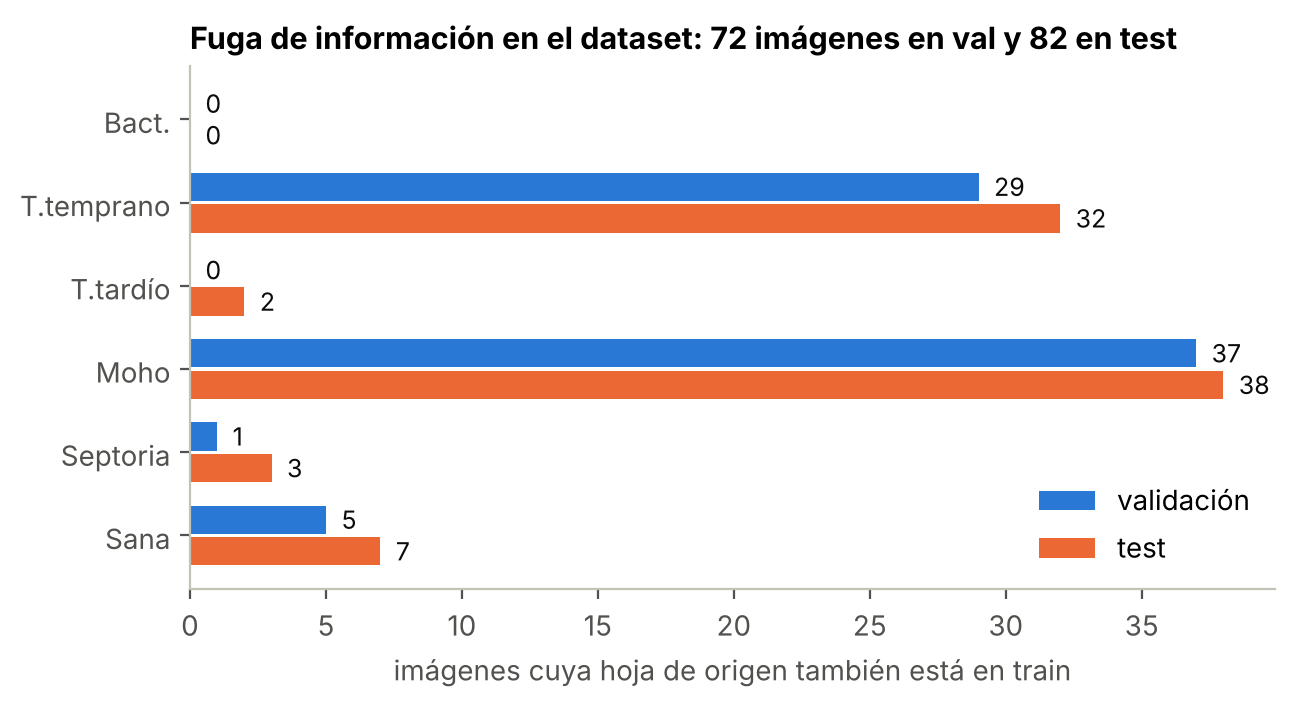

In [ ]:
fuga = pd.read_csv(R / "fuga_resumen.csv")
fuga["clase"] = fuga["class"].map(CLASES_ES)
tabla = fuga.pivot_table(index="clase", columns="split", values=["aumentadas", "contaminadas"], aggfunc="sum")
display(tabla)
for s in ["val", "test"]:
    d = idx[idx.split == s]
    print(f"{s}: {int(d.leak.sum())} de {len(d)} imágenes contaminadas ({100*d.leak.mean():.1f} %)")
display(Image(filename=str(FIG / "c2_01_fuga_por_clase.png")))

Encontramos 72 fotos contaminadas en validación y 82 en test, casi todas de tizón temprano y moho de la hoja, que eran las clases con más copias.

Lo que decidimos fue no mover ni borrar nada de las carpetas originales, sino crear lo que llamamos la validación limpia. Es la misma validación pero sin esas 72 fotos, así que queda con 909. Todas las decisiones de este corte se toman con la validación limpia: cuál es la mejor época de entrenamiento de cada modelo, cuál modelo gana y cuál elegimos al final. La validación completa, con las 981 fotos, la seguimos reportando solo para ver cuánto inflaba la fuga los resultados.

Otra regla importante es que la aumentación de datos se hace solo en entrenamiento. Aumentar los datos significa que, en cada vuelta del entrenamiento, a las fotos se les aplican cambios al azar: se recortan un poco, se voltean, se giran hasta 20 grados y se les cambia ligeramente el brillo, el contraste y la saturación. Así el modelo aprende a reconocer la enfermedad y no una foto exacta. Lo que casi no tocamos fue el tono del color, porque el color de las manchas es una pista importante para distinguir las enfermedades y no queríamos alterarlo. A las fotos de validación y test no se les hace nada de esto: solo se reducen a 224 por 224 píxeles, para evaluar con fotos tal como llegarían en la realidad.

### Preguntas de reflexión

1. ¿El esquema de validación se parece al uso real del modelo?

En parte sí. Después de quitar la fuga, las fotos de validación son hojas que el modelo de verdad nunca vio. Pero todas las fotos del dataset se tomaron en condiciones muy parecidas: una sola hoja, sobre un fondo liso y con buena luz. En la vida real, alguien tomaría la foto con el celular en el cultivo, con otras hojas detrás, sombras y luz cambiante. Es muy probable que ahí el modelo funcione peor, y por eso lo dejamos como uno de los riesgos al final.

2. ¿Hay riesgo de que una misma condición aparezca de forma engañosa en train y test?

Sí, y de hecho lo comprobamos con la fuga que acabamos de explicar. Pero queda otro riesgo más difícil de ver. Los nombres de los archivos dejan ver que las fotos se tomaron en distintas sesiones, y hay sesiones que aparecen tanto en entrenamiento como en validación. Dos hojas diferentes fotografiadas el mismo día, con el mismo fondo, la misma cámara y la misma luz, se parecen mucho entre sí, y eso le puede facilitar la tarea al modelo. Con la información que trae el dataset no podemos separar las fotos por sesión, así que lo reconocemos como una limitación.

3. ¿Qué variable podría causar fuga si se usa sin cuidado?

El nombre del archivo, porque trae la clase y la sesión, y las copias de una misma hoja repartidas entre grupos. El nombre no lo usamos nunca como entrada, y las copias las controlamos con la validación limpia.

4. ¿Qué pasaría si solo reportáramos el desempeño en entrenamiento?

Nos engañaríamos por completo. En entrenamiento casi todos los modelos buenos sacan prácticamente 1,00, que es la nota perfecta. Con solo ese número no podríamos ver que el SVM del Corte 1 baja a 0,965 cuando le mostramos fotos nuevas, mientras que la mejor red se mantiene en 0,999. Tampoco podríamos darnos cuenta de si un modelo está memorizando las fotos en lugar de aprender. Por eso siempre hay que medir con fotos que el modelo no haya visto.

---
# 3. Línea base y primer modelo

Antes de probar modelos complicados, necesitamos puntos de referencia para saber si de verdad estamos mejorando. Volvimos a evaluar los dos modelos del Corte 1, esta vez con la validación limpia.

El primero es el modelo Dummy, que es una línea base ingenua: no mira la foto para nada y siempre responde la clase que más se repite en entrenamiento. Sirve para saber cuánto se saca sin aprender nada.

El segundo es el SVM, nuestro primer modelo de verdad. Es un modelo clásico de aprendizaje automático que trabaja con los 58 números que describen el color y la textura de cada hoja, y busca la mejor forma de separar las seis clases usando esos números.

In [ ]:
cols = ["modelo", "train_macroF1", "val_macroF1_completo", "val_macroF1_limpio", "brecha_train_val",
        "F1_T.temprano", "F1_T.tardío", "recall_Sana"]
bench[bench.run.isin(["dummy", "svm_hsv_lbp"])][cols]

,modelo,train_macroF1,val_macroF1_completo,val_macroF1_limpio,brecha_train_val,F1_T.temprano,F1_T.tardío,recall_Sana
5,SVM HSV+LBP (Corte 1),0.9978,0.9671,0.9647,0.0331,0.9304,0.9177,0.9937
8,Dummy (mayoritaria),0.0478,0.0477,0.0509,-0.0031,0.0000,0.0000,0.0000


### Preguntas de reflexión

1. ¿Qué predice la línea base?

Siempre lo mismo. Como no mira las fotos, siempre dice la clase más común. Como las seis clases tienen casi la misma cantidad de fotos, acierta más o menos una de cada seis veces, y su macro-F1 es de apenas 0,051. Ese es el piso: cualquier modelo que valga la pena tiene que estar muy por encima.

2. ¿La mejora del primer modelo es grande, pequeña o marginal?

Es enorme. El SVM pasa de 0,051 a 0,965 de macro-F1 en la validación limpia. Algo interesante es que con la validación completa, la que tenía fuga, sacaba 0,967. O sea que la fuga casi no lo afectaba, y el resultado que reportamos en el Corte 1 era básicamente real. Ahora lo podemos afirmar con evidencia en lugar de suponerlo.

3. ¿El modelo simple es fácil de explicar a una persona que no sabe de inteligencia artificial?

Sí, bastante. Se le puede decir algo como: el modelo mira qué tanto verde, amarillo y café tiene la hoja y cómo es la textura de las manchas, y lo compara con muchos ejemplos que ya conoce. Es muy parecido a como un agrónomo describiría una hoja enferma, así que es fácil de entender y de confiar.

4. Si el modelo simple tiene límites, ¿qué hipótesis tenemos?

El SVM se equivoca 32 veces en las 909 fotos, y 14 de esos errores son confusiones entre tizón temprano y tizón tardío. Nuestra hipótesis es que el problema está en la forma en que describimos las fotos. Un histograma de color nos dice cuánto café hay en la hoja, pero no nos dice cómo está organizado ese café. Y justamente ahí está la diferencia entre los dos tizones: el temprano forma manchas más pequeñas con anillos, como una diana, mientras que el tardío forma manchas grandes y difusas que avanzan desde el borde. Las dos enfermedades tienen mucho café, así que para el SVM se ven casi iguales.

También notamos que el SVM tiene la diferencia más grande entre entrenamiento y validación de todos los modelos: 0,998 contra 0,965. Eso indica que memoriza un poco las fotos de entrenamiento sin lograr generalizar del todo. Por eso pensamos que un modelo capaz de ver la forma de las manchas y no solo los colores, como una red neuronal convolucional, debería resolver esta confusión.

---
# 4. Benchmark de modelos

Un benchmark es una comparación justa entre varios modelos. Para que sea justa, todos usan las mismas fotos de entrenamiento y validación, la misma preparación de imágenes para evaluar, la misma semilla aleatoria y las mismas métricas. Las redes neuronales las entrenamos en una tarjeta gráfica GTX 1650, de a 32 fotos por paso, y con parada temprana: si un modelo pasa varias épocas sin mejorar en la validación limpia, se detiene y nos quedamos con su mejor época.

Comparamos nueve modelos, que se pueden agrupar así:

- El Dummy, como piso mínimo.
- El SVM con color y textura, que es el modelo base del Corte 1.
- Una red neuronal pequeña entrenada desde cero, con 1,2 millones de parámetros. Sirve para ver si una red sencilla, sin ninguna experiencia previa, ya supera al SVM.
- MobileNetV3 y EfficientNet-B0 congelados. Son redes que ya fueron entrenadas con millones de fotos de todo tipo, en un dataset llamado ImageNet, y por eso ya saben reconocer bordes, texturas y formas. En el modo congelado no tocamos nada de lo que ya saben y solo entrenamos la última capa, la que decide la clase. Es la opción más barata.
- MobileNetV3, EfficientNet-B0 y ResNet-18 con ajuste fino, que en inglés se llama fine-tuning. Aquí partimos de las mismas redes preentrenadas, pero reajustamos toda la red para que se especialice en hojas de tomate. Es más costoso, pero suele dar mejores resultados. ResNet-18 es una red más grande y clásica que incluimos como punto de comparación.

En cuanto al ajuste de hiperparámetros, que son las perillas que uno escoge antes de entrenar, no hicimos una búsqueda a ciegas. El valor más importante es la tasa de aprendizaje, que controla qué tan grandes son los pasos con que el modelo corrige sus errores. Usamos 0,001 para los modelos congelados y para la red pequeña, porque tienen pocas cosas que ajustar, y 0,0003 para el ajuste fino, porque ahí se mueve toda la red y conviene ir con más cuidado. En EfficientNet, que antes de empezar parecía el candidato más fuerte, probamos además 0,0001 para ver qué tan sensible era el resultado a ese valor.

In [ ]:
cols = ["modelo", "familia", "params_M", "entrenables_M", "tiempo_entreno_min", "ms_por_imagen", "mejor_epoca",
        "train_macroF1", "val_macroF1_completo", "val_macroF1_limpio", "brecha_train_val",
        "F1_T.temprano", "F1_T.tardío", "recall_Sana"]
bench[cols]

,modelo,familia,params_M,entrenables_M,tiempo_entreno_min,ms_por_imagen,mejor_epoca,train_macroF1,val_macroF1_completo,val_macroF1_limpio,brecha_train_val,F1_T.temprano,F1_T.tardío,recall_Sana
0,ResNet-18 fine-tune,transfer_finetune,11.180,11.180,7.35,4.249,15.0,1.0000,0.9990,0.9989,0.0011,0.9963,0.9969,1.0000
1,MobileNetV3 fine-tune,transfer_finetune,4.210,4.210,7.82,11.255,10.0,0.9998,0.9980,0.9978,0.0020,1.0000,0.9969,1.0000
2,EfficientNet-B0 fine-tune (lr 3e-4),transfer_finetune,4.015,4.015,13.67,10.665,11.0,0.9993,0.9969,0.9978,0.0015,0.9963,0.9938,1.0000
3,EfficientNet-B0 fine-tune (lr 1e-4),transfer_finetune,4.015,4.015,11.78,18.025,14.0,0.9998,0.9969,0.9968,0.0030,0.9963,0.9908,1.0000
4,CNN pequeña (desde cero),cnn_scratch,1.175,1.175,21.77,3.286,27.0,0.9902,0.9796,0.9783,0.0119,0.9627,0.9605,0.9874
5,SVM HSV+LBP (Corte 1),clásico,0.093,0.093,0.00,0.130,NaN,0.9978,0.9671,0.9647,0.0331,0.9304,0.9177,0.9937
6,MobileNetV3 congelado,transfer_frozen,4.210,1.238,5.58,15.438,8.0,0.9743,0.9594,0.9626,0.0117,0.9513,0.9477,0.9686
7,EfficientNet-B0 congelado,transfer_frozen,4.015,0.008,5.93,13.830,8.0,0.9361,0.9210,0.9227,0.0134,0.8676,0.9164,1.0000
8,Dummy (mayoritaria),referencia,0.000,0.000,0.00,0.001,NaN,0.0478,0.0477,0.0509,-0.0031,0.0000,0.0000,0.0000


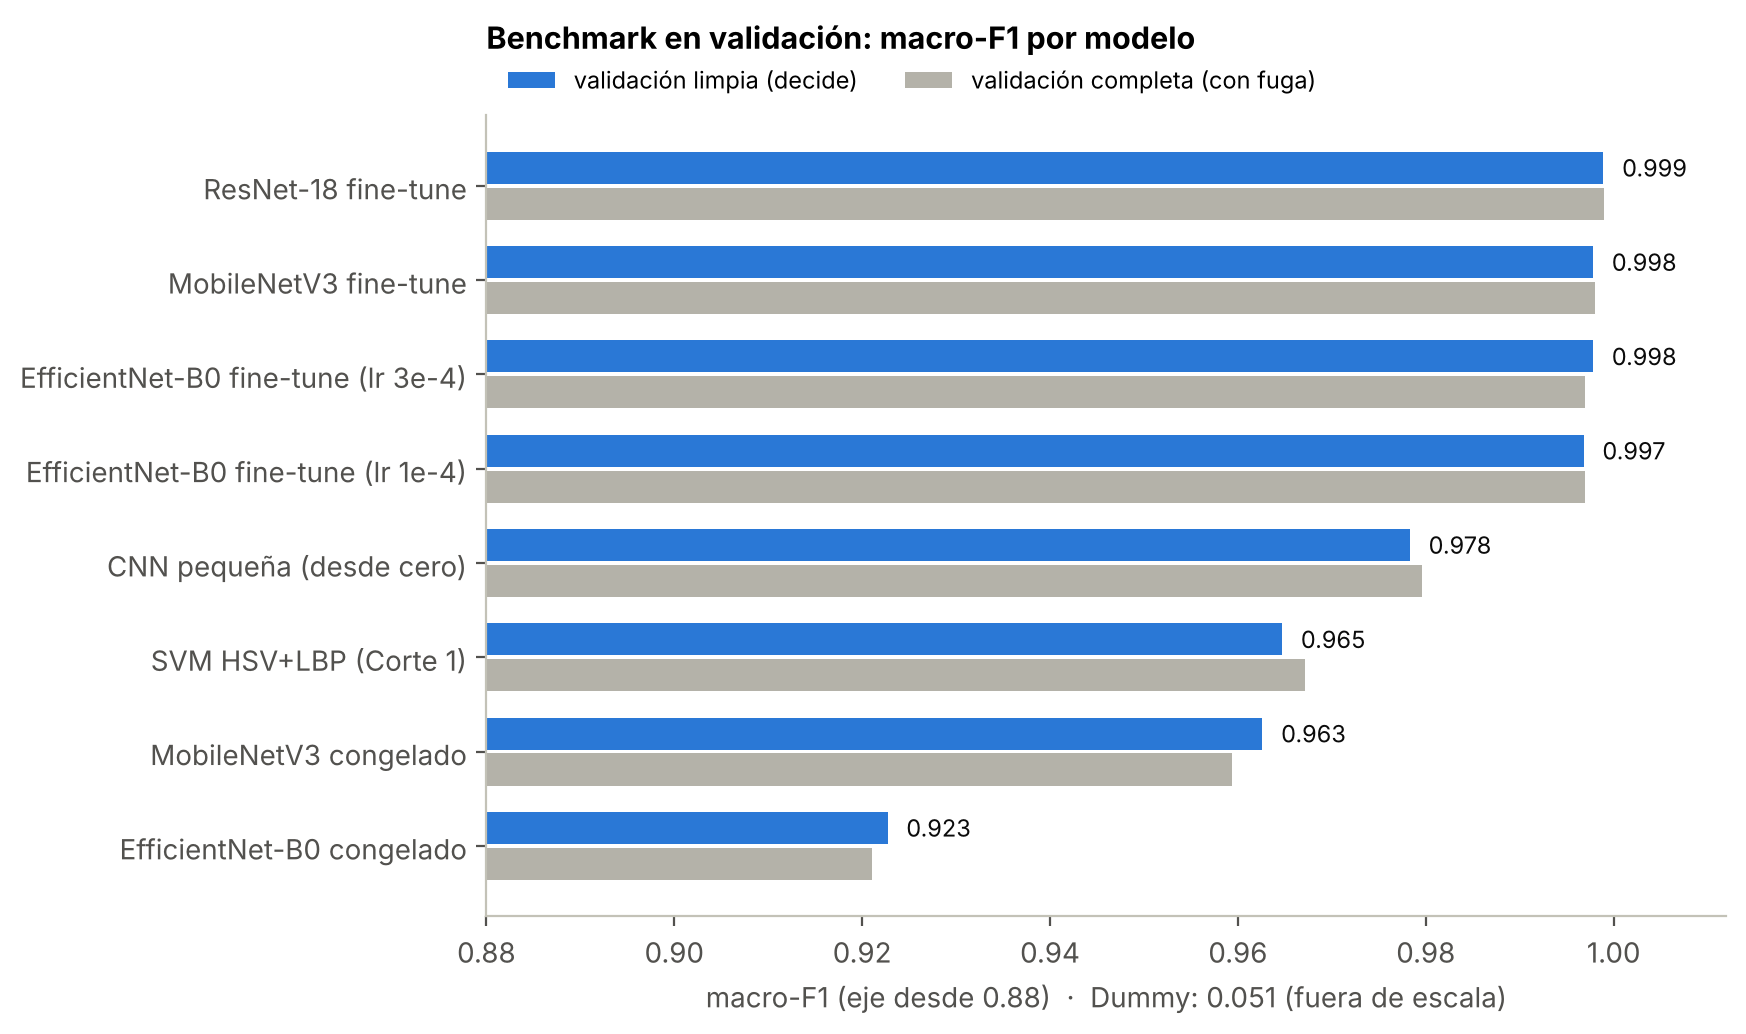

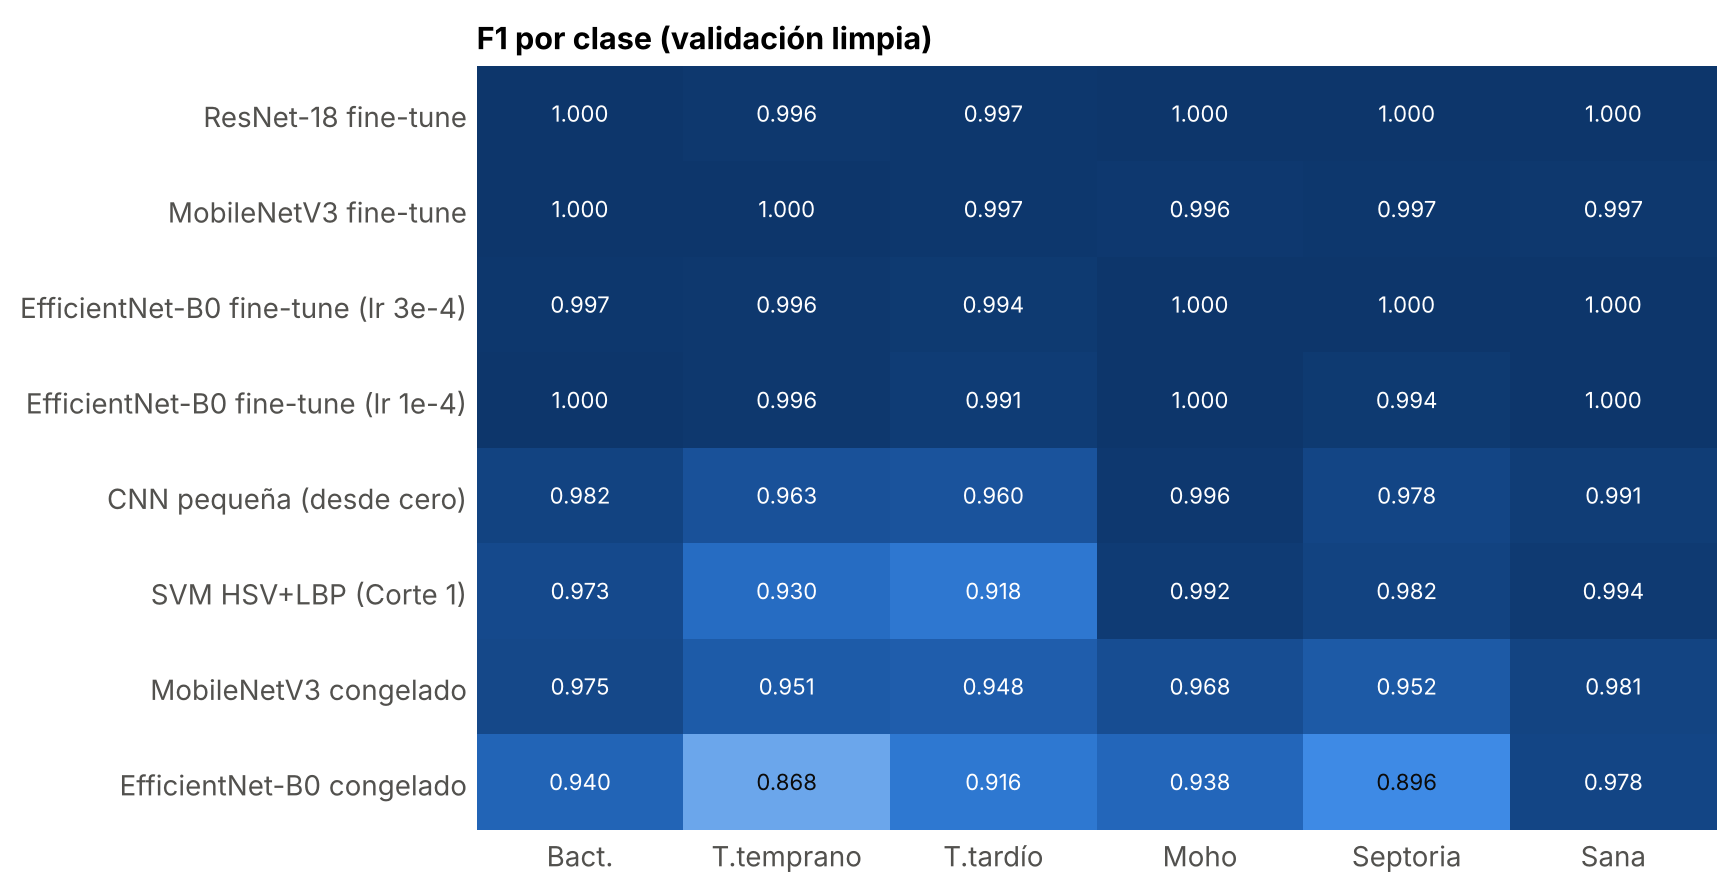

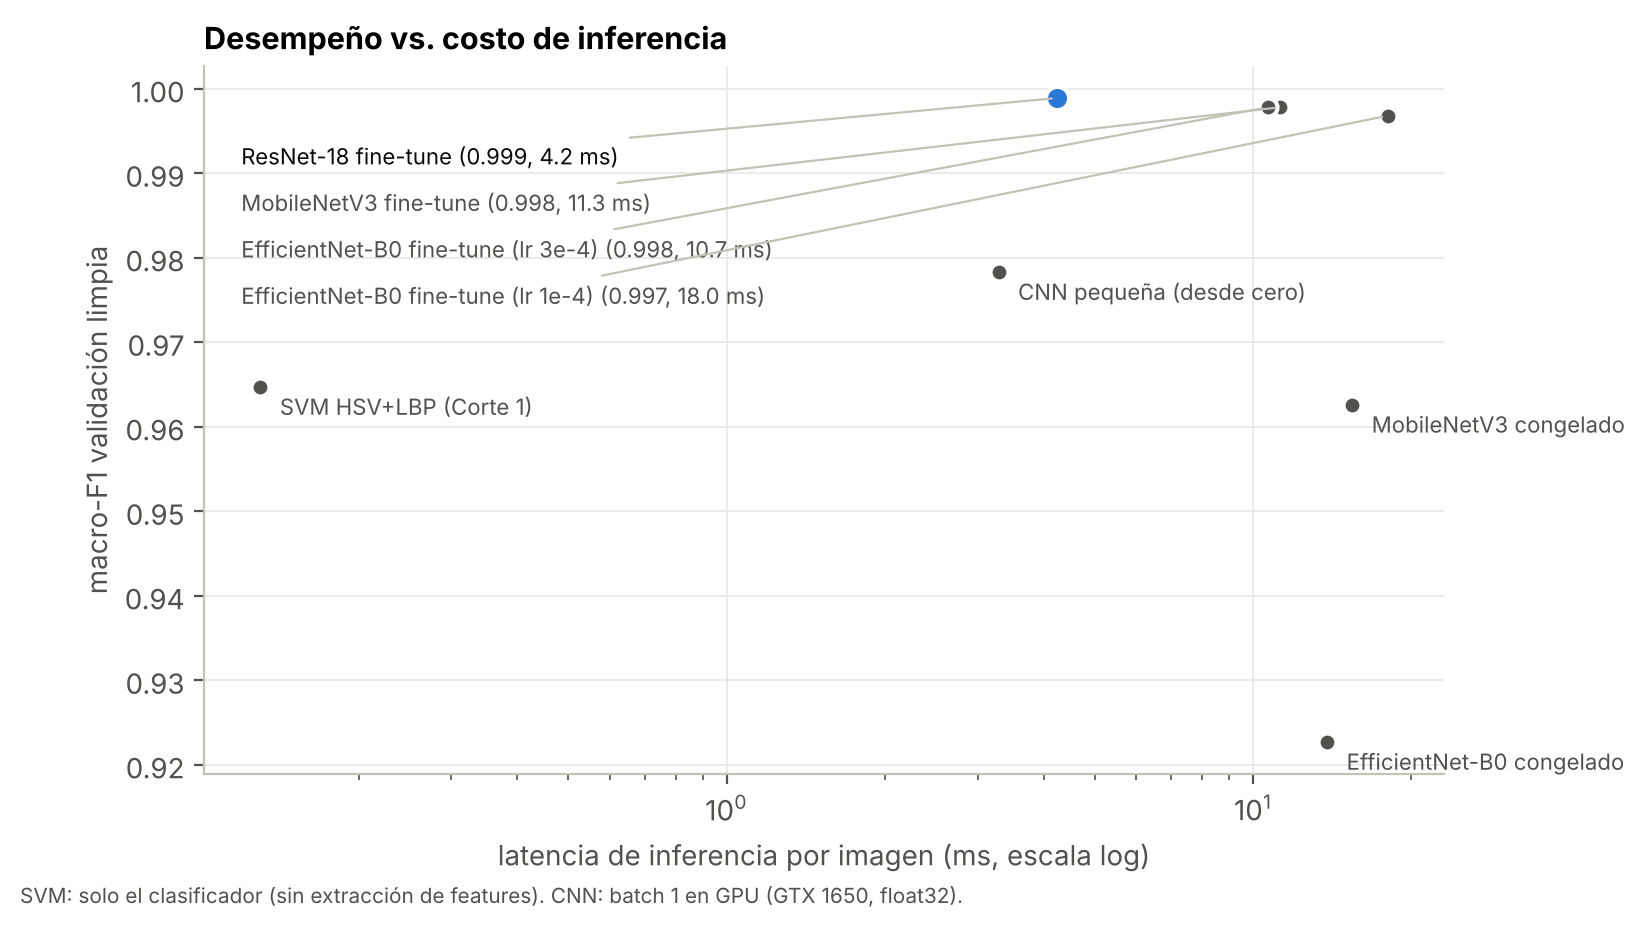

In [ ]:
display(Image(filename=str(FIG / "c2_02_benchmark_macroF1.png")))
display(Image(filename=str(FIG / "c2_04_f1_por_clase.png")))
display(Image(filename=str(FIG / "c2_03_desempeno_vs_costo.png")))

In [ ]:
# Significancia: mejor modelo vs. baseline (validación limpia, 909 imágenes)
print(f"Mejor por métrica: {sig['mejor']}  vs  baseline: {sig['baseline']}")
print(f"  macro-F1 {sig['macroF1_mejor']:.4f}  IC95 bootstrap [{sig['IC95_mejor'][0]:.4f}, {sig['IC95_mejor'][1]:.4f}]")
print(f"  macro-F1 {sig['macroF1_baseline']:.4f}  IC95 bootstrap [{sig['IC95_baseline'][0]:.4f}, {sig['IC95_baseline'][1]:.4f}]")
print(f"  errores: {sig['errores_mejor']} vs {sig['errores_baseline']}  | corrige {sig['corregidos_por_mejor']}, "
      f"introduce {sig['nuevos_errores_del_mejor']}  | McNemar p = {sig['mcnemar_p']:.2g}")

# McNemar entre los mejores modelos (¿la diferencia entre CNN con fine-tune es real?)
from scipy.stats import binomtest
top = ["resnet18_finetune_lr0.0003", "mobilenet_v3_large_finetune_lr0.0003",
       "efficientnet_b0_finetune_lr0.0003", "efficientnet_b0_finetune_lr0.0001", "smallcnn_scratch_lr0.001"]
P = {r: pd.read_csv(R / "runs" / r / "preds_val.csv").set_index("rel_path") for r in top}
limpias = P[top[0]].index[P[top[0]].clean]
ok = {r: (P[r].loc[limpias, "pred"] == P[r].loc[limpias, "label"]).to_numpy() for r in top}
filas = []
for r in top[1:]:
    b = int((ok[top[0]] & ~ok[r]).sum()); c = int((~ok[top[0]] & ok[r]).sum())
    filas.append({"comparado con ResNet-18": r, "errores del otro": int((~ok[r]).sum()),
                  "solo falla el otro": b, "solo falla ResNet-18": c,
                  "McNemar p": round(binomtest(min(b, c), b + c, 0.5).pvalue, 4) if b + c else 1.0})
pd.DataFrame(filas)

Mejor por métrica: resnet18_finetune_lr0.0003  vs  baseline: svm_hsv_lbp
  macro-F1 0.9989  IC95 bootstrap [0.9959, 1.0000]
  macro-F1 0.9647  IC95 bootstrap [0.9519, 0.9757]
  errores: 1 vs 32  | corrige 31, introduce 0  | McNemar p = 9.3e-10


,comparado con ResNet-18,errores del otro,solo falla el otro,solo falla ResNet-18,McNemar p
0,mobilenet_v3_large_finetune_lr0.0003,2,2,1,1.000
1,efficientnet_b0_finetune_lr0.0003,2,2,1,1.000
2,efficientnet_b0_finetune_lr0.0001,3,3,1,0.625
3,smallcnn_scratch_lr0.001,20,19,0,0.000


### Preguntas de reflexión

1. ¿Qué modelo tuvo mejor desempeño según la métrica principal?

El mejor fue ResNet-18 con ajuste fino. Sacó 0,999 de macro-F1 en la validación limpia, lo que significa que de las 909 fotos solo se equivocó en una. Muy cerca quedaron MobileNetV3 y EfficientNet-B0 con ajuste fino, los dos con 0,998 y dos errores cada uno.

2. ¿La diferencia frente al segundo modelo es importante o marginal?

Entre los cuatro modelos con ajuste fino la diferencia es mínima: uno tiene un error, otros dos tienen dos y el último tiene tres. Para saber si una diferencia así es real o es pura suerte, usamos la prueba de McNemar. Esta prueba compara dos modelos foto por foto y se fija en los casos donde uno acierta y el otro falla. Si esos casos están muy desbalanceados hacia un lado, la diferencia es real. Si están parejos, puede ser casualidad. Entre los modelos con ajuste fino la prueba dice que no hay diferencia real, así que no podemos afirmar que ResNet-18 sea mejor que MobileNetV3 o que EfficientNet. Están empatados.

Frente al SVM la historia es muy distinta. ResNet-18 corrige 31 de los 32 errores del SVM y no comete ni un solo error nuevo. La prueba de McNemar dice que la probabilidad de que esto sea suerte es de más o menos una en mil millones. También calculamos intervalos de confianza, que son un rango donde probablemente está el valor real del macro-F1 si tuviéramos muchas más fotos. Para el SVM ese rango va de 0,952 a 0,976, y para ResNet-18 va de 0,996 a 1,000. Los dos rangos no se tocan, lo que confirma que la mejora es real.

3. ¿El modelo más complejo realmente justifica su complejidad?

Depende de cuál complejidad. El ajuste fino sí se justifica, porque elimina justo el error que más nos preocupaba: las 14 confusiones entre los dos tizones desaparecen y el F1 de esas clases pasa de 0,93 y 0,92 a casi 1,00.

En cambio, usar las redes congeladas no se justifica. MobileNetV3 congelado saca 0,963, prácticamente igual que el SVM, y EfficientNet-B0 congelado saca 0,923, que es peor. Además a los dos les va mal incluso en entrenamiento, lo que se conoce como subajuste: el modelo no tiene suficiente capacidad para aprender la tarea. Lo que nos dice esto es que lo que estas redes aprendieron de fotos generales no basta para distinguir manchas tan parecidas, y hay que dejar que la red se adapte a las hojas. En EfficientNet congelado el problema es más fuerte porque solo se entrena una capa muy pequeña, de unos 8 mil parámetros, mientras que la última parte de MobileNetV3 tiene 1,2 millones.

La red pequeña entrenada desde cero supera al SVM, con 0,978, pero se queda lejos de las redes preentrenadas: tiene 20 errores y además fue la que más se demoró en entrenar, unos 22 minutos. Con solo 4.600 fotos, empezar desde cero no alcanza para aprender tan bien como una red que ya traía experiencia.

Por último, vimos que más grande no significa mejor. ResNet-18 tiene 11 millones de parámetros y MobileNetV3 tiene 4 millones, y quedaron empatados. Lo que realmente marca la diferencia es partir de una red preentrenada y reajustarla completa.

4. ¿Qué modelo sería más fácil de explicar y mantener?

El más transparente sigue siendo el SVM, porque sus 58 números tienen un significado claro, se entrena en segundos y no necesita tarjeta gráfica. Entre las redes, ResNet-18 es la más sencilla de entender por dentro y una de las más estudiadas, y existen herramientas como Grad-CAM, que vamos a usar en el Corte 3, para ver en qué parte de la hoja se fijó la red al tomar su decisión.

5. ¿Qué modelo escogeríamos si el contexto exigiera más transparencia?

Escogeríamos el SVM, sabiendo que confunde los dos tizones, y le agregaríamos una regla para que una persona revise siempre que el modelo diga tizón temprano o tizón tardío. Si se puede usar una red, una parte de la transparencia se recupera con los mapas de Grad-CAM, que muestran qué zona de la hoja llevó a cada diagnóstico.

Un detalle sobre el costo que nos sorprendió: en nuestra tarjeta gráfica, ResNet-18 fue la red más rápida, con 4,2 milisegundos por foto, a pesar de ser la más grande. MobileNetV3 y EfficientNet se demoraron cerca de 11 milisegundos. La explicación es que esas dos redes están diseñadas para funcionar rápido en el procesador de un celular, no en una tarjeta gráfica de computador. En un celular probablemente el orden se invertiría, pero eso no lo medimos en este corte.

---
# 5. Análisis de errores y generalización

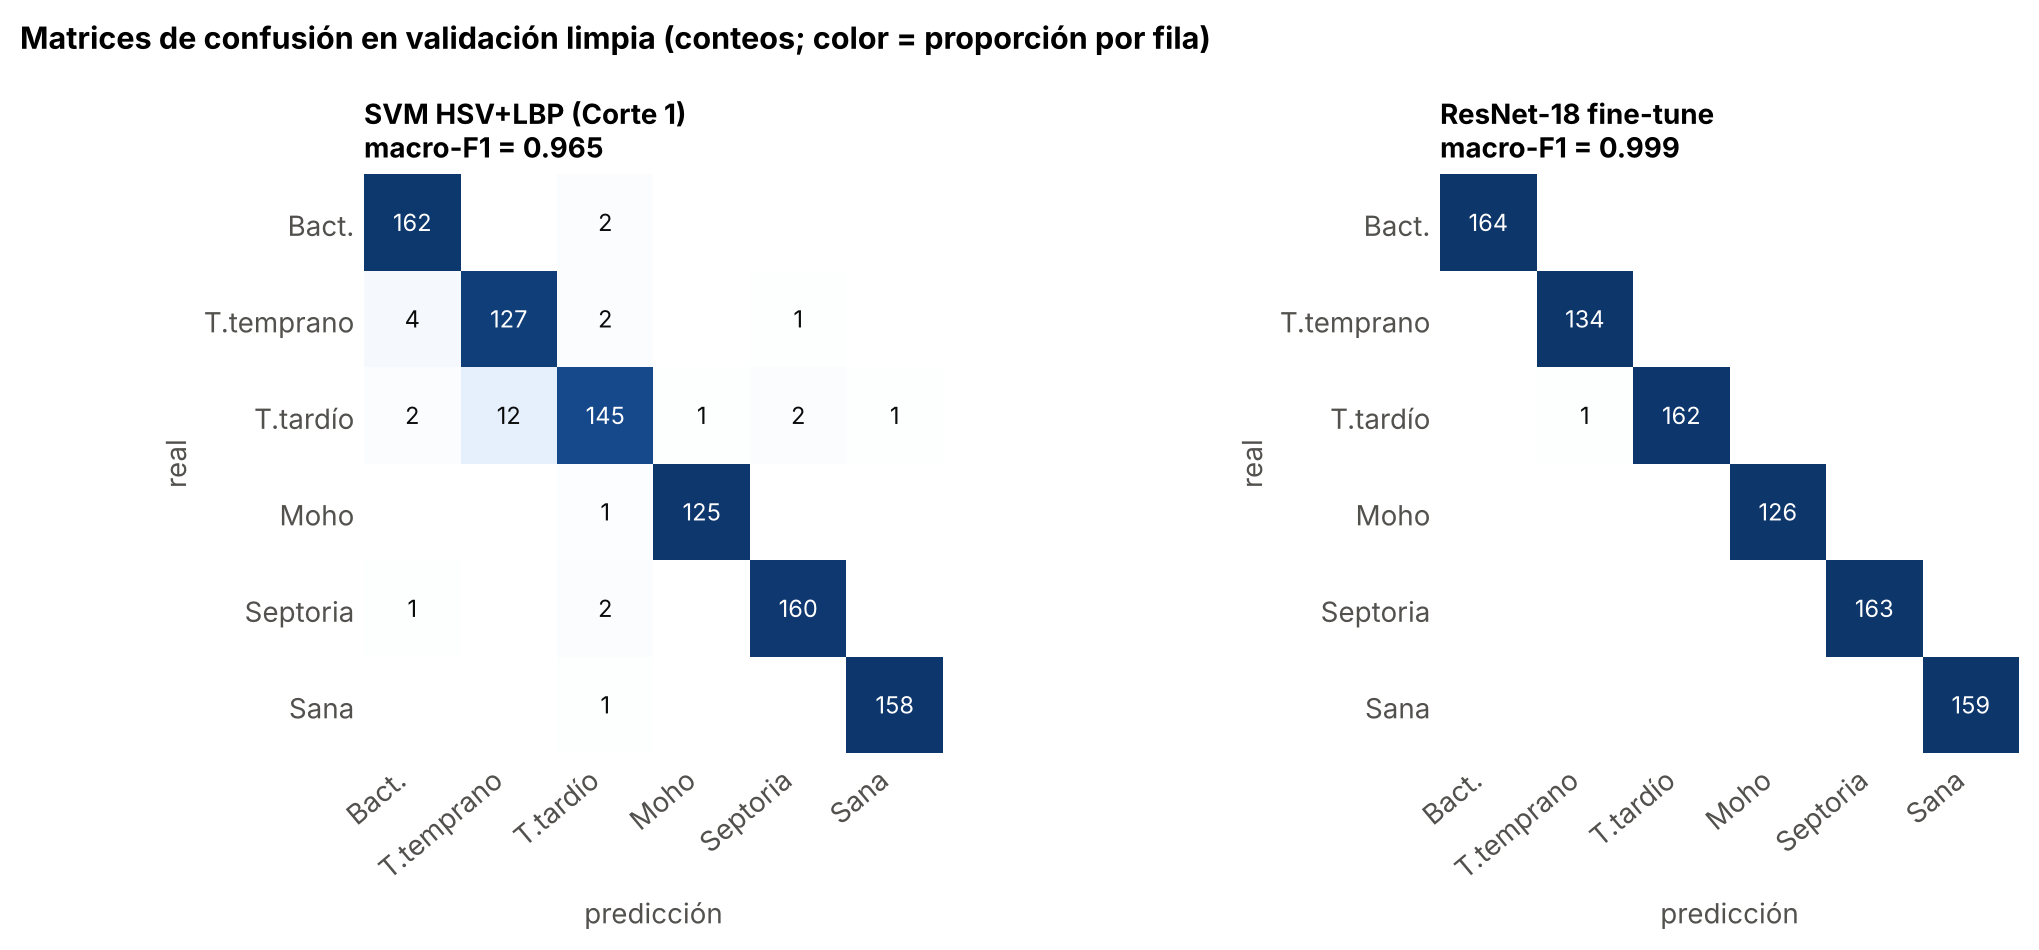

In [ ]:
display(Image(filename=str(FIG / "c2_05_confusion_baseline_vs_mejor.png")))

Errores del SVM que ResNet-18 corrige, por tipo de confusión (real -> predicción del SVM):


,,casos
real,pred_baseline,
T.tardío,T.temprano,11
T.temprano,Bact.,4
T.tardío,Bact.,2
Septoria,T.tardío,2
Bact.,T.tardío,2
T.temprano,T.tardío,2
T.tardío,Septoria,2
Moho,T.tardío,1
Sana,T.tardío,1


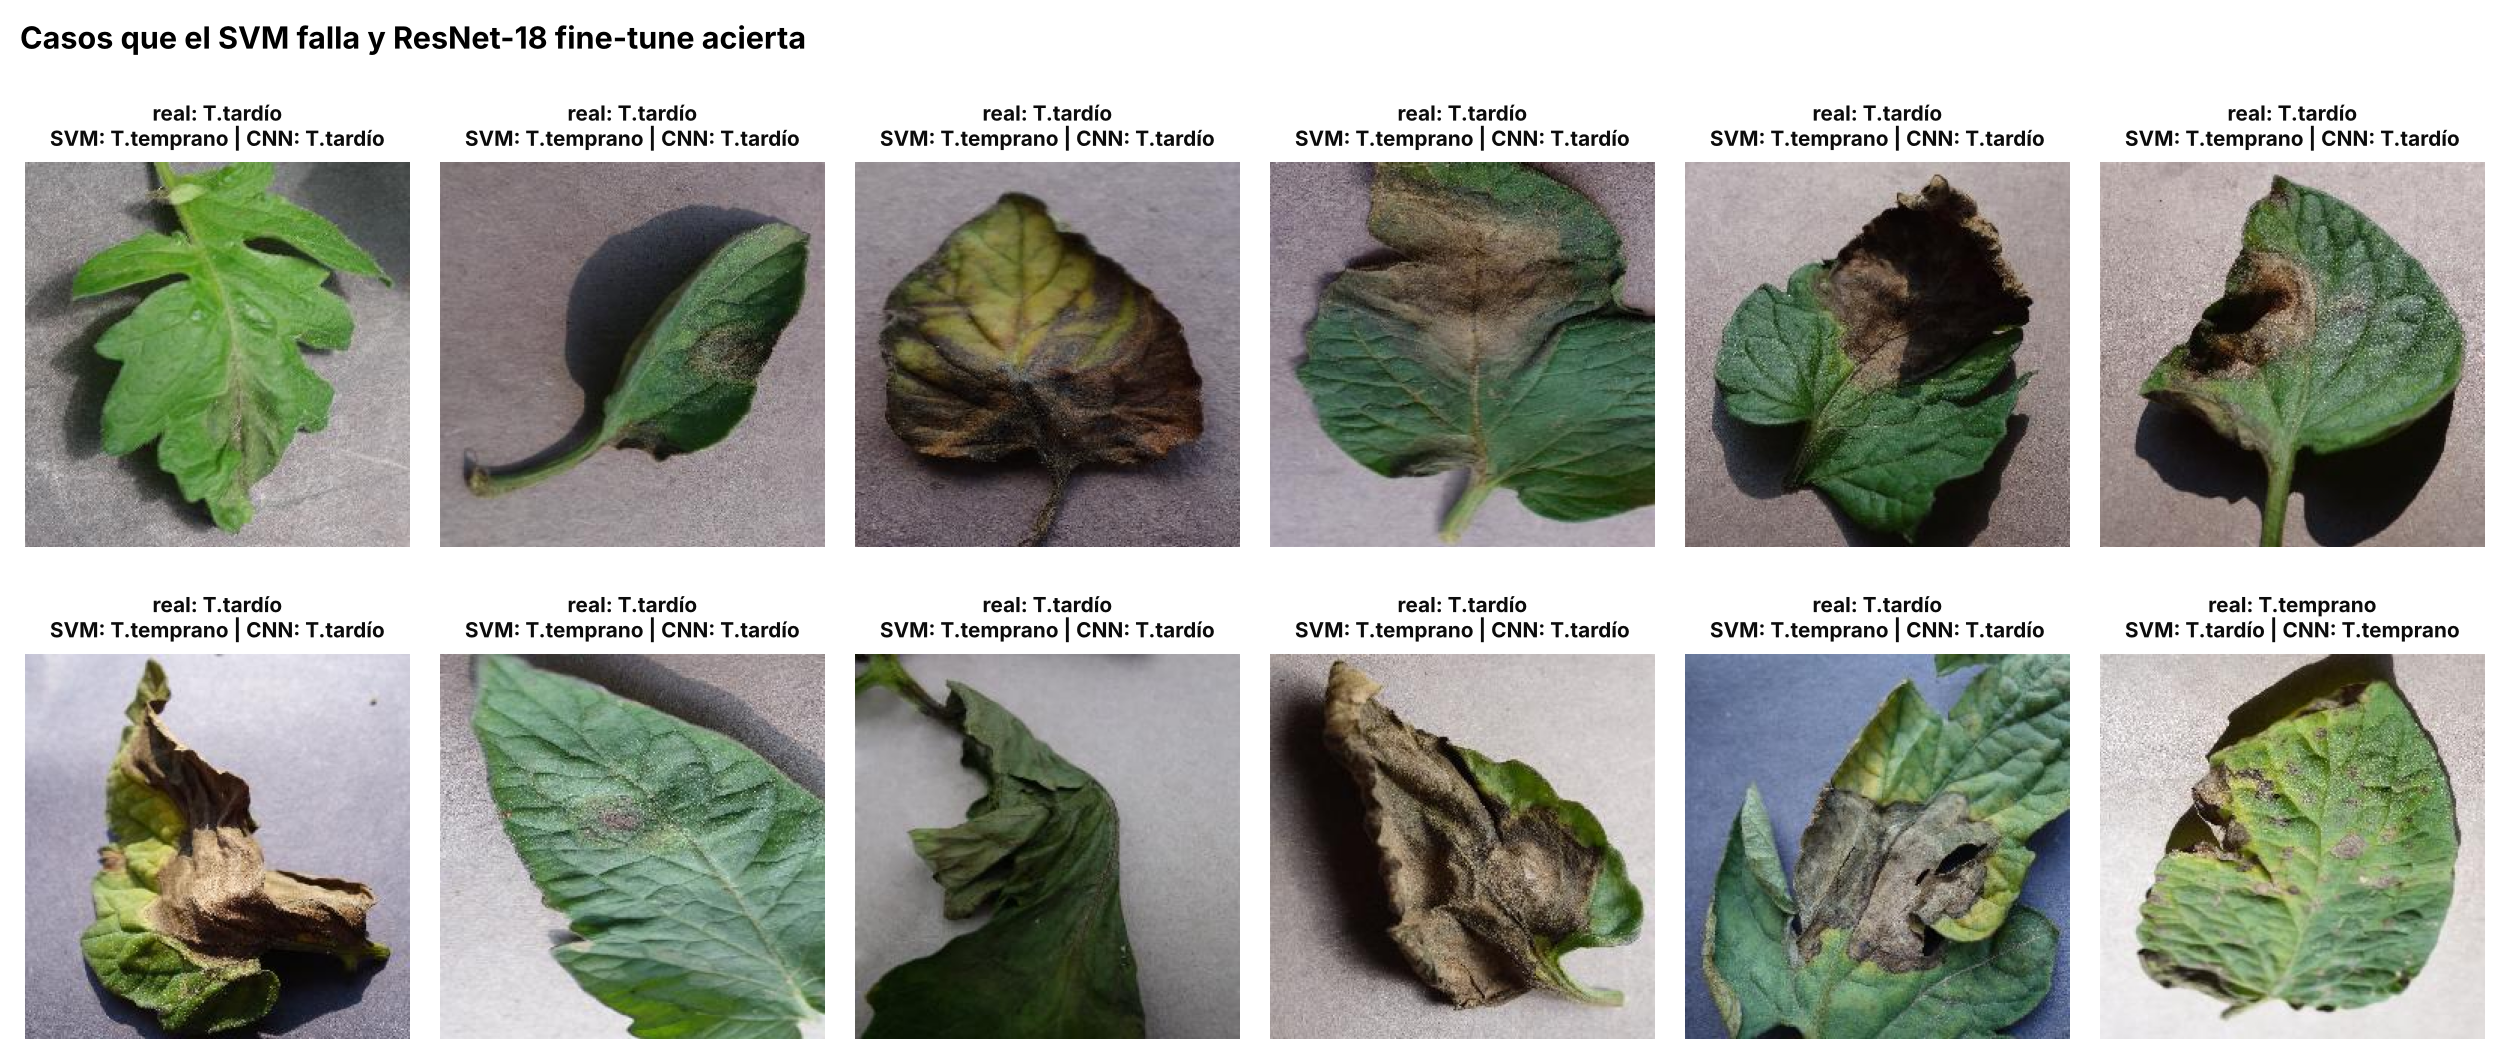

In [ ]:
cmp = pd.read_csv(R / "comparacion_errores.csv")
print("Errores del SVM que ResNet-18 corrige, por tipo de confusión (real -> predicción del SVM):")
display(cmp[cmp.tipo == "corregido_por_mejor"].groupby(["real", "pred_baseline"]).size()
        .sort_values(ascending=False).rename("casos").to_frame())
display(Image(filename=str(FIG / "c2_08_errores_corregidos.png")))

,modelo,real,predicción,confianza,archivo
0,resnet18_finetune_lr0.0003,T.tardío,T.temprano,0.541,d6027b84-ede4-4b4a-b76b-3fa65f4e663c___RS_Late...
1,mobilenet_v3_large_finetune_lr0.0003,T.tardío,Sana,0.513,d67013bf-2462-4626-a4fa-e352e7d3008b___GHLB2ES...
2,mobilenet_v3_large_finetune_lr0.0003,Moho,Septoria,0.583,876b7bac-c03b-468e-a7c8-67a3c2ba2526___Crnl_L....
3,efficientnet_b0_finetune_lr0.0003,T.tardío,Bact.,0.923,15581dd8-f562-4301-856c-30be9302c470___GHLB2 L...
4,efficientnet_b0_finetune_lr0.0003,T.tardío,T.temprano,0.999,697751e5-f4d4-448e-bf98-656ebfd01ba5___RS_Late...
5,efficientnet_b0_finetune_lr0.0001,T.tardío,T.temprano,0.997,697751e5-f4d4-448e-bf98-656ebfd01ba5___RS_Late...
6,efficientnet_b0_finetune_lr0.0001,T.tardío,Septoria,0.306,78122366-5c83-4d3f-97b0-b7135181738b___GHLB Le...
7,efficientnet_b0_finetune_lr0.0001,Septoria,T.tardío,0.743,cd3b1a93-f5b4-406f-aa8a-640280edf543___Keller....


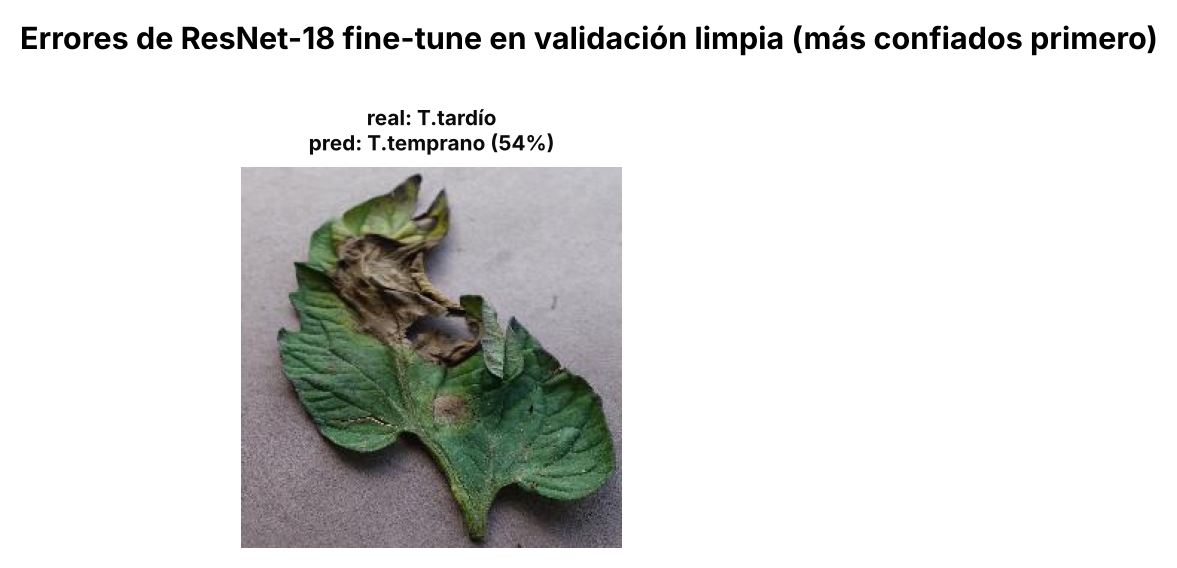

In [ ]:
# Errores de los modelos con fine-tune en validación limpia, con su confianza
nombres = ["Bact.", "T.temprano", "T.tardío", "Moho", "Septoria", "Sana"]
filas = []
for r in top[:4]:
    p = pd.read_csv(R / "runs" / r / "preds_val.csv")
    p = p[p.clean & (p.pred != p.label)]
    for _, e in p.iterrows():
        filas.append({"modelo": r, "real": nombres[e.label], "predicción": nombres[e.pred],
                      "confianza": round(e[[f"prob_{i}" for i in range(6)]].max(), 3),
                      "archivo": e.rel_path.split("/")[-1]})
display(pd.DataFrame(filas))
display(Image(filename=str(FIG / "c2_07_errores_mejor_modelo.png")))

In [ ]:
# ¿Sirve la confianza para decidir cuándo pedir revisión humana? (ResNet-18, validación limpia)
p = pd.read_csv(R / "runs" / "resnet18_finetune_lr0.0003" / "preds_val.csv")
p = p[p.clean]
conf = p[[f"prob_{i}" for i in range(6)]].max(axis=1)
err = p.pred != p.label
pd.DataFrame([{"umbral de confianza": t, "casos marcados para revisión": int((conf < t).sum()),
               "% de las imágenes": round(100 * (conf < t).mean(), 1),
               "errores capturados": f"{int((err & (conf < t)).sum())} de {int(err.sum())}"} for t in [0.7, 0.8, 0.9]])

,umbral de confianza,casos marcados para revisión,% de las imágenes,errores capturados
0,0.7,4,0.4,1 de 1
1,0.8,6,0.7,1 de 1
2,0.9,13,1.4,1 de 1


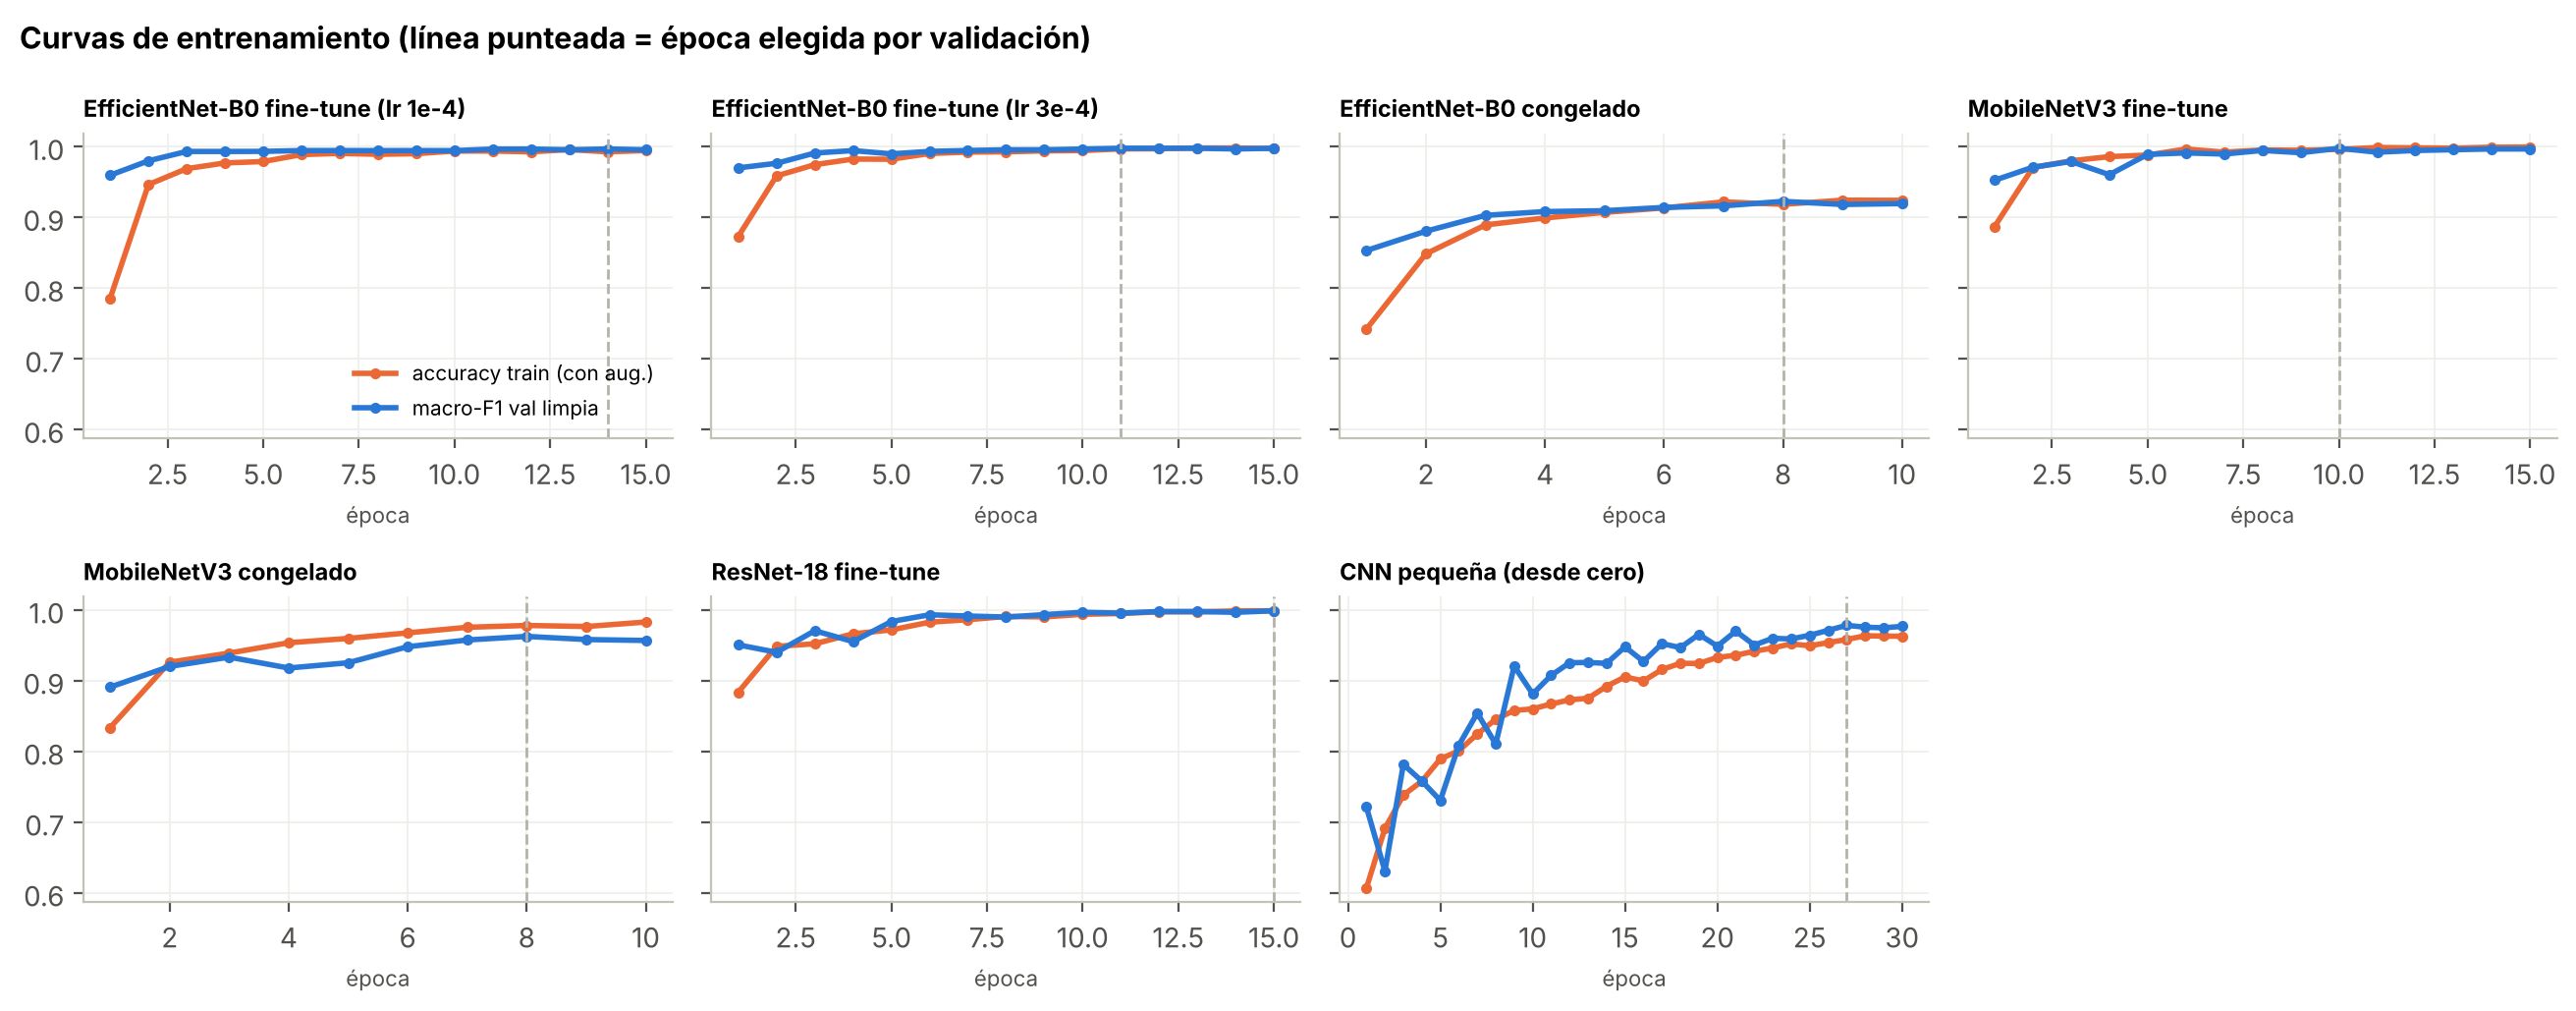

In [ ]:
display(Image(filename=str(FIG / "c2_06_curvas_entrenamiento.png")))

### Matriz de confusión, falsos positivos y falsos negativos

Una matriz de confusión es una tabla donde cada fila es la clase real de la hoja y cada columna es lo que dijo el modelo. Si el modelo fuera perfecto, todos los números estarían en la diagonal. Todo lo que queda por fuera de la diagonal es un error, y la tabla nos dice exactamente qué confundió con qué.

En la matriz del SVM se ven 32 errores. El grupo más grande es de hojas con tizón tardío que el modelo llamó tizón temprano: 12 casos, y hay otros 2 al revés. Además, el tizón tardío funciona como una especie de cajón de sastre: otras 8 hojas de distintas clases terminaron clasificadas como tizón tardío. Y lo más preocupante es que hay una hoja con tizón tardío que el SVM dijo que estaba sana, que es el error más grave según lo que definimos en la sección 1.

En la matriz de ResNet-18 solo hay un error: una hoja con tizón tardío que el modelo llamó tizón temprano, y lo dijo con apenas 54 por ciento de confianza, es decir, estaba dudando. Si uno mira la foto, la hoja tiene una zona grande seca y arrugada que se parece al tejido muerto del tizón temprano cuando ya está avanzado, así que es un caso difícil hasta para una persona. Lo más importante es que ResNet-18 no dijo que ninguna hoja enferma estuviera sana. En la clase que más nos preocupa, el tizón tardío, cada vez que el modelo dijo tizón tardío acertó, y encontró 162 de las 163 hojas que lo tenían.

MobileNetV3, que quedó empatado, tiene dos errores. Uno es una hoja con moho que llamó Septoria. El otro es una hoja con tizón tardío que dijo que estaba sana, y resulta que es la misma hoja que el SVM también llamó sana. Seguramente es una hoja con la enfermedad apenas empezando, donde casi no se ve.

### Diferencia entre entrenamiento y validación

Comparar cómo le va a un modelo en entrenamiento y en validación nos ayuda a saber si está aprendiendo bien. Si le va muy bien en entrenamiento pero mucho peor en validación, está memorizando las fotos en lugar de aprender, y eso se llama sobreajuste. Si le va regular en los dos, no está logrando aprender la tarea, y eso se llama subajuste.

| Modelo | Train | Validación limpia | Diferencia | Qué significa |
|---|---:|---:|---:|---|
| SVM | 0,998 | 0,965 | 0,033 | sobreajuste moderado, memoriza un poco |
| EfficientNet-B0 congelado | 0,936 | 0,923 | 0,013 | subajuste, no aprende bien ni el entrenamiento |
| MobileNetV3 congelado | 0,974 | 0,963 | 0,012 | subajuste leve |
| Red pequeña desde cero | 0,990 | 0,978 | 0,012 | aprende bien, pero le falta capacidad |
| Los cuatro con ajuste fino | casi 1,000 | entre 0,997 y 0,999 | 0,003 o menos | generalizan bien dentro de este dataset |

Las curvas de entrenamiento muestran lo mismo de forma visual. En los modelos con ajuste fino, la línea de entrenamiento y la de validación suben juntas y nunca se separan. ResNet-18 encontró su mejor resultado en la última época, la número 15, así que nunca se activó la parada temprana. Podría seguir mejorando con más épocas, pero como ya tiene un solo error, eso no cambiaría la conclusión.

### Desbalance de clases

Un dataset está desbalanceado cuando hay muchas más fotos de unas clases que de otras. Eso puede hacer que el modelo se vuelva perezoso y le apueste siempre a la clase más común. En nuestro caso no pasa: cada clase tiene alrededor de 765 fotos en entrenamiento, así que no tuvimos que hacer ningún ajuste especial. El único pequeño desbalance lo causó la limpieza de la fuga: en la validación limpia, tizón temprano y moho quedaron con 134 y 126 fotos, mientras que las demás clases tienen unas 160, porque eran las clases que tenían más copias. Por eso preferimos el macro-F1 sobre el porcentaje de aciertos, ya que el macro-F1 le da el mismo peso a todas las clases sin importar cuántas fotos tengan.

### Preguntas de reflexión

1. ¿Hay señales de subajuste?

Sí, en los modelos congelados, sobre todo en EfficientNet-B0 congelado, que solo saca 0,936 en entrenamiento. Si a un modelo le va regular incluso con las fotos que ya vio, es porque no tiene la capacidad de aprender la tarea.

2. ¿Hay señales de sobreajuste?

En el SVM sí, de forma moderada, porque su diferencia entre entrenamiento y validación es la más grande de todos. En los modelos con ajuste fino no vemos sobreajuste dentro de este dataset. Pero hay que tener cuidado: un resultado de 0,999 es tan alto que también es una señal de alerta. Puede significar que, en estas condiciones de laboratorio, la tarea es más fácil de lo que sería en un cultivo real, o que las sesiones de fotos que se repiten entre grupos le están ayudando al modelo. Por eso todavía falta la prueba final con test en el Corte 3 y, ojalá, una prueba con fotos tomadas por nosotros.

3. ¿Los errores parecen aleatorios o sistemáticos?

En el SVM son claramente sistemáticos, o sea que siguen un patrón: casi todos tienen que ver con los tizones y se explican por la forma en que describimos las fotos, con histogramas que no ven la forma de las manchas. En las redes con ajuste fino quedan tan pocos errores, entre uno y tres, que no se puede hablar de un patrón, aunque casi todos involucran al tizón tardío. Un detalle importante: EfficientNet-B0 se equivocó en una foto de tizón tardío diciendo tizón temprano con 99,9 por ciento de seguridad. Eso significa que fijarse en la confianza del modelo no siempre sirve para atrapar sus errores. En ResNet-18 sí sirve, porque su único error lo cometió dudando, con 54 por ciento.

4. ¿Qué casos debería revisar una persona antes de confiar en el modelo?

Proponemos tres reglas. La primera es revisar las fotos donde el modelo tenga menos de 90 por ciento de confianza. Con ResNet-18 eso son 13 de 909 fotos, más o menos una de cada setenta, y entre ellas está su único error. La segunda es revisar cualquier diagnóstico de tizón temprano o tardío, porque es la confusión más costosa. La tercera es revisar las hojas con daño muy extenso o muy secas, y cualquier foto que no sea de una hoja sola sobre un fondo liso, porque son situaciones distintas a las que el modelo conoce.

---
# 6. Conclusión técnica, riesgos y documentación de IA

Nuestro modelo recomendado, por ahora, es ResNet-18 preentrenado con ImageNet y con ajuste fino de toda la red, entrenado con una tasa de aprendizaje de 0,0003 durante 15 épocas y con aumentación solo en las fotos de entrenamiento. Decimos que es provisional porque todavía falta la prueba final con test en el Corte 3.

¿Por qué este y no otro? Frente al SVM la decisión es fácil: corrige 31 de sus 32 errores, incluidas las 14 confusiones entre tizones, y la prueba estadística confirma que la mejora no es casualidad.

Frente a MobileNetV3 y EfficientNet-B0 con ajuste fino la decisión es más difícil, porque en desempeño están empatados. Para desempatar nos fijamos en cuatro cosas. Primero, ResNet-18 es el más rápido en nuestra tarjeta gráfica, con 4,2 milisegundos por foto contra unos 11 de los otros dos. Segundo, no dijo que ninguna hoja enferma estuviera sana, mientras que MobileNetV3 sí lo hizo una vez. Tercero, su único error lo cometió dudando, así que una regla de confianza lo puede atrapar, mientras que EfficientNet se equivocó estando 99,9 por ciento seguro. Cuarto, es una red sencilla y muy estudiada, lo que facilita el trabajo de interpretabilidad del Corte 3. Su desventaja es el tamaño: tiene 11 millones de parámetros y ocupa unos 45 megas, contra unos 17 de MobileNetV3. Si el objetivo fuera usarlo en un celular, MobileNetV3 sería probablemente la mejor opción, pero habría que medir su velocidad directamente en el teléfono.

Frente a los modelos congelados y la red pequeña la decisión también es clara, porque les va bastante peor, ya sea porque no logran aprender bien o porque no tienen suficiente capacidad.

La métrica principal fue el macro-F1 en la validación limpia, porque le da el mismo peso a las seis clases y no deja que las clases fáciles escondan la confusión entre los tizones. La complementamos con el F1 de cada tizón y con qué tan bien se detectan las hojas sanas.

Comparado con las líneas base, el avance va de 0,051 con el Dummy, a 0,965 con el SVM, a 0,999 con ResNet-18. Si tuviéramos muchas más fotos, lo más probable es que el valor real de ResNet-18 estuviera entre 0,996 y 1,000.

Como evidencia de que generaliza bien tenemos tres cosas: la diferencia entre entrenamiento y validación es de 0,003 o menos, los cuatro modelos con ajuste fino dan resultados muy parecidos entre sí y con distintas tasas de aprendizaje, y todo se midió después de quitar la fuga de información.

Ahora, los riesgos y limitaciones. El primero es que todas las fotos son de laboratorio: una hoja sola, sobre un fondo liso, con buena luz. No sabemos cómo se comporta el modelo con fotos tomadas en el cultivo. El segundo es que, aunque quitamos las copias de una misma hoja, todavía hay hojas distintas de una misma sesión de fotos repartidas entre los grupos, con el mismo fondo, la misma luz y la misma cámara, y eso puede hacerle la tarea más fácil al modelo. El tercero es que el modelo siempre responde una de las seis clases. Si le mostramos una hoja con otra enfermedad, como el virus del mosaico, una hoja de otra planta o una foto que ni siquiera es de una hoja, va a responder igual de seguro, pero sin sentido. El cuarto es que todavía no hemos hecho la evaluación final: el 0,999 es un poco optimista porque elegimos el modelo usando esas mismas fotos de validación.

¿Cuándo sí usaríamos el modelo? Como una herramienta de apoyo para un técnico o un agricultor, no como reemplazo de una persona. Funcionaría con fotos de una sola hoja sobre un fondo claro y liso, con buena luz, y para las cinco enfermedades que conoce. Además, una persona revisaría los casos con menos de 90 por ciento de confianza y todos los diagnósticos de tizón.

¿Cuándo no lo usaríamos? Con fotos tomadas directamente en el cultivo, con fondos complicados o varias hojas, con otras enfermedades u otros cultivos, para decidir automáticamente aplicar un fungicida sin que nadie lo revise, o como única prueba para decir que una planta está sana.

### Preguntas de reflexión

1. ¿Qué falta validar antes de usar el modelo fuera del aula?

Falta la evaluación final con test, que haremos en el Corte 3. También queremos probarlo con fotos tomadas por nosotros o de otro dataset de fotos de campo, medir qué tan rápido funciona en el dispositivo donde se usaría, por ejemplo un celular, y revisar con Grad-CAM que la red realmente esté mirando la mancha de la hoja y no el fondo de la foto.

2. ¿Cada cuánto habría que monitorear su desempeño?

Si se hiciera una prueba piloto, lo ideal sería que cada semana un experto revisara una muestra de fotos y comparara su diagnóstico con el del modelo, y que se vigilara si la confianza del modelo empieza a bajar. Además, habría que volver a evaluarlo cada temporada de cultivo, porque cambian la luz, las variedades de tomate y las enfermedades que más aparecen.

3. ¿Qué cosas podrían cambiar con el tiempo y afectar la calidad del modelo?

La cámara y la resolución de las fotos, el fondo y la iluminación, la variedad de tomate, qué tan avanzada está la enfermedad cuando se toma la foto, y la aparición de enfermedades que el modelo no conoce.

4. ¿Qué advertencia debería aparecer en el README o en la ficha del modelo?

Algo como esto: este modelo fue entrenado con fotos de laboratorio, de una hoja sola sobre un fondo liso, para seis clases. No reconoce enfermedades distintas a esas ni ha sido probado en campo. Es una herramienta de apoyo. Confirme con un experto cualquier diagnóstico de tizón y cualquier predicción con menos de 90 por ciento de confianza.

### Bitácora de uso de IA generativa (Corte 2)
La bitácora completa está en `AI_USE_LOG.md`. En resumen: se usó Claude (Anthropic) para orientar el diseño del pipeline del Corte 2 (`src/c2_*.py`), detectar la fuga de información en el dataset, configurar el entorno PyTorch + CUDA en Windows y ayudo a redactar un primer borrador del análisis de este cuaderno especialmente apartados de codigos complejos. Todo el entrenamiento se ejecutó en el PC del equipo con el dataset real; las cifras de este cuaderno se leen directamente de los archivos generados (`reports/corte2/`).

---
## Lista de chequeo antes de entregar

- [x] Cargué correctamente el dataset, con un índice de 6.557 imágenes.
- [x] Declaré que uso datos propios, de Mendeley y PlantVillage, con licencia CC BY 4.0.
- [x] Formulé una tarea clara de clasificación multiclase.
- [x] Justifiqué la variable objetivo y las variables predictoras.
- [x] Evité la fuga de información: la detecté en el dataset original y la controlé con la validación limpia.
- [x] Separé entrenamiento y validación, y dejé el test reservado para el Corte 3.
- [x] Comparé contra una línea base, el Dummy, y contra el modelo clásico, el SVM.
- [x] Comparé nueve modelos de forma justa, con las mismas fotos y las mismas métricas.
- [x] Reporté métricas adecuadas: macro-F1, F1 por clase, matriz de confusión, intervalos de confianza y prueba de McNemar.
- [x] Analicé los errores y la generalización con la diferencia entre entrenamiento y validación, las curvas y las galerías de errores.
- [x] Escribí una conclusión técnica y no solo una tabla.
- [x] Declaré el uso de IA generativa.